# Exercise 2: neural-network regression and uncertainty in reflectometry

**From fitting a curve to learning from many examples**

In the morning, you used **Anaklasis** to infer structural parameters from
reflectivity measurements. In Exercise 1, you learned how a neural network
makes predictions and adjusts its weights. We now bring these ideas together.

We will predict the scattering length density (**SLD**) of a single layer
from its reflectivity curve. The other structural parameters also vary.
Our first prediction is one number. Later, we ask how much confidence to
place in that number.

By the end, you should be able to:

1. Train and evaluate a small neural-network regressor.
2. Explain how training duration and the number of examples affect overfitting.
3. Interpret predicted uncertainty and check whether intervals are useful.

**How to use this notebook:** run cells in order. Tasks marked **Predict**,
**Run**, and **Explain** guide the experiments. The default settings provide
a complete CPU example. Ex1 supplies the introduction to neurons, activations,
gradients, and optimization; here we focus on the inverse problem.

## 0. The bridge from conventional fitting

A physical forward model maps structure to a reflectivity curve:

$$\boldsymbol\theta \longrightarrow R(Q).$$

Conventional inference, including Anaklasis, repeatedly evaluates a forward
model to find parameters compatible with a measurement. It can also explore
parameter uncertainty, for example using MCMC.

Supervised learning starts with many simulated examples whose parameters
are known. Training builds a statistical inverse mapping:

$$R(Q) \longrightarrow \widehat{\mathrm{SLD}}.$$

Simulation and training incur an initial cost. Evaluating a trained network
is then fast. Its predictions depend on the structures and curve conditions
represented in training. The network does not establish physical uniqueness
or validate a fitted structure merely by producing a number.

**Predict:** if two different structures produce very similar curves,
what could a network trained with squared error predict for their SLD?

**Instructor answer — a point prediction for an ambiguous inverse problem**

If the input cannot reliably distinguish the structures, squared-error training
favours the **conditional mean SLD**, averaged over the alternatives according to
their probabilities in the simulation population. For two equally likely SLD
values of 2 and 10, the optimal squared-error prediction would be 6, in the same
units. This average need not correspond to either structure or to a structure
whose forward-model curve matches the measurement. Similar curves are not
necessarily indistinguishable; the answer depends on the information available
to the model.

## 1. Meet the data

The supplied dataset contains **3,169 curves on a common grid of 1001 Q values**.


| Target column | Meaning | Used as network input? |
|---|---|---|
| 0 | Fronting roughness | No |
| 1 | Layer SLD: our prediction target | No |
| 2 | Layer thickness | No |
| 3 | Layer roughness | No |
| 4 | Constant zero; unused | No |

The only input is the reflectivity curve. The fixed Q grid gives each input
position the same physical meaning across samples. No further interpolation
or learned encoder is required in this exercise.

**Data scope:** the supplied pickle contains curves, structural labels, and Q.
It does not provide pointwise measurement uncertainties or a complete
simulation/noise recipe. We therefore do not attribute every prediction
error to measurement noise. The sampling distribution of these simulations supplies implicit prior information about likely parameters.

In [1]:
from pathlib import Path
from copy import deepcopy
from time import perf_counter
import pickle

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from tqdm import tqdm

%matplotlib inline

# Small models can run faster with a few CPU threads than with many.
torch.set_num_threads(2)
torch.manual_seed(1)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
SLD_UNIT = 1e-6  # Display SLD in units of 10^-6 A^-2.
print(f"PyTorch {torch.__version__}; NumPy {np.__version__}; device: CPU")

PyTorch 2.4.0; NumPy 1.26.4; device: CPU


In [2]:
# Run Jupyter with Ex2 as the working directory. 
data_path = Path("data") / "data_reflectometry_1L.pkl"
with data_path.open("rb") as handle:
    X, t, q = pickle.load(handle)                                # load data

X, t, q = map(np.asarray, (X, t, q))                             # converts the variables X, t, and q into NumPy arrays if they aren't already
assert X.ndim == 2 and t.shape == (len(X), 5)                    # if the condition is true, the program continues running normally
assert q.shape == (X.shape[1],) and np.all(np.diff(q) > 0)
assert np.isfinite(X).all() and (X > 0).all()
assert np.isfinite(t).all() and (t[:, 4] == 0).all()

duplicate_curves = len(X) - len(np.unique(X, axis=0))            # check for duplicate curves
duplicate_parameters = len(t) - len(np.unique(t[:, :4], axis=0)) # check for duplicate parameters
assert duplicate_curves == 0 and duplicate_parameters == 0

print("Curves:", X.shape, "| targets:", t.shape)
print(f"Q range: {q.min():.3f} to {q.max():.3f} A^-1")
print("Exact duplicate curves: %g,   Exact duplicate parameter vectors: %g"
      %(duplicate_curves, duplicate_parameters))

Curves: (3169, 1001) | targets: (3169, 5)
Q range: 0.001 to 0.300 A^-1
Exact duplicate curves: 0,   Exact duplicate parameter vectors: 0


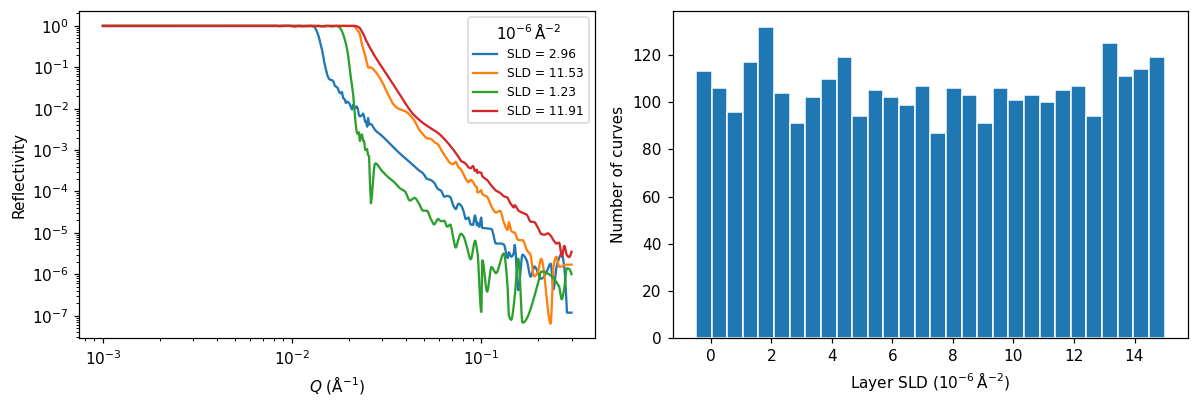

In [3]:
example_idx = [0, 10, 20, 30]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for i in example_idx:
    axes[0].loglog(q, X[i], label=f"SLD = {t[i, 1] / SLD_UNIT:.2f}")
axes[0].set(xlabel=r"$Q$ ($\mathrm{\AA}^{-1}$)", ylabel="Reflectivity")
axes[0].legend(title=r"$10^{-6}\,\mathrm{\AA}^{-2}$", fontsize=8)
axes[1].hist(t[:, 1] / SLD_UNIT, bins=30, edgecolor="white")
axes[1].set(xlabel=r"Layer SLD ($10^{-6}\,\mathrm{\AA}^{-2}$)",
            ylabel="Number of curves")
plt.tight_layout()
plt.show()

### Prepare inputs, targets, and independent data partitions

Reflectivity spans many orders of magnitude, so the input is $\log_{10}R$.
All supplied values are positive; no clipping is needed.

We split the examples into **60% training, 20% validation, and 20% test**.

- **Training:** adjusts the network weights and supplies scaling statistics.
- **Validation:** compares settings and selects a checkpoint.
- **Test:** independently evaluates selected models, without influencing training. 

Each Q feature and the SLD target are standardized using training means and
standard deviations. Validation and test data receive the same transformation.
No physical target value is an input. Because the supplied parameter vectors
are unique, we find no repeated structures with exactly the same four labels;
this check cannot establish the full simulation provenance.

In [4]:
train_idx, rest_idx = train_test_split(
    np.arange(len(X)), test_size=0.4, random_state=1
)
val_idx, test_idx = train_test_split(
    rest_idx, test_size=0.5, random_state=1
)

x = np.log10(X)
y = t[:, 1:2]  # Keep shape (number of curves, 1).
x_scaler = StandardScaler().fit(x[train_idx])        # scikit-learn's StandardScaler: scaling data to have a mean of 0 and a standard deviation of 1)
y_scaler = StandardScaler().fit(y[train_idx])

def to_tensor(array):
    return torch.tensor(array, dtype=torch.float32)

xtr = to_tensor(x_scaler.transform(x[train_idx]))
xvl = to_tensor(x_scaler.transform(x[val_idx]))
xte = to_tensor(x_scaler.transform(x[test_idx]))
ytr = to_tensor(y_scaler.transform(y[train_idx]))
yvl = to_tensor(y_scaler.transform(y[val_idx]))
yte = to_tensor(y_scaler.transform(y[test_idx]))

def physical_sld(scaled_values, scaler=y_scaler):
    return np.asarray(scaled_values) * scaler.scale_[0] + scaler.mean_[0]

print("Training / validation / test:", len(train_idx), len(val_idx), len(test_idx))
print("Training tensors:", tuple(xtr.shape), tuple(ytr.shape))
print("Training target mean / standard deviation (10^-6 A^-2):",
      np.round(np.array([y_scaler.mean_[0], y_scaler.scale_[0]]) / SLD_UNIT, 3))     # 3 represents the number of decimal places to which will be rounded

Training / validation / test: 1901 634 634
Training tensors: (1901, 1001) (1901, 1)
Training target mean / standard deviation (10^-6 A^-2): [7.133 4.556]


## Exercise 2.1: train a point predictor

We use the same basic building blocks as Ex1: a linear hidden layer,
sigmoid activation, and a linear output. The output predicts standardized
SLD. With squared error, the ideal statistical prediction is a **conditional
mean**, which need not identify a unique physical solution.

$$\mathrm{MSE}=\frac{1}{N}\sum_i(\hat y_i-y_i)^2.$$

First establish a simple reference: always predict the mean SLD of the
training examples. In standardized coordinates, this prediction is zero.

**Predict:** should a trained network beat this constant predictor? What
would it mean if training improved but validation did not?

**Instructor answers — predicting performance before training**

1. **Beating the constant predictor:** this is expected if reflectivity contains
   useful information about SLD and the network learns it from the supplied
   examples. It is not guaranteed by using a neural network. The constant predictor
   ignores the curve completely; a useful regressor changes its prediction with
   the information in the curve.
2. **Training improves but validation does not:** the training improvement is not
   transferring to new examples. A growing gap, especially when validation loss
   rises, is evidence of overfitting. Training loss alone cannot establish useful
   generalization. Validation guides checkpoint selection; the test partition
   subsequently evaluates the selected model independently of that selection.

In [5]:
validation_baseline = (yvl**2).mean().item()
print(f"Validation MSE of training-mean predictor: {validation_baseline:.3f}")

def make_network(hidden_size=64, outputs=1, seed=1):
    torch.manual_seed(seed)
    return nn.Sequential(
        nn.Linear(xtr.shape[1], hidden_size),
        nn.Sigmoid(),
        nn.Linear(hidden_size, outputs)
    )

print(make_network())

Validation MSE of training-mean predictor: 1.047
Sequential(
  (0): Linear(in_features=1001, out_features=64, bias=True)
  (1): Sigmoid()
  (2): Linear(in_features=64, out_features=1, bias=True)
)


### A visible training loop

The function below packages the familiar steps so later experiments can
reuse them. Read the loop once: predict, calculate loss, clear gradients,
backpropagate, update weights, and evaluate without gradients.

`model.eval()` changes the model's operating mode; `torch.no_grad()` avoids
recording gradients during evaluation. We save an independent copy of the
weights whenever validation loss improves. We continue training to display
possible overfitting, then restore that checkpoint. This is checkpoint
selection; it does not stop computation early.

Weight decay discourages large weights. The histories below report **MSE
only**, so regularization does not create an artificial train/validation gap.

In [6]:
def train_mse(model, train_inputs, train_targets, val_inputs, val_targets,
              test_inputs, test_targets,  
              epochs=4000, learning_rate=2e-4, weight_decay=1e-2):
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(
        model.parameters(), lr=learning_rate, weight_decay=weight_decay
    )
    history = np.empty((epochs, 3))  
    best_loss = float("inf")
    start = perf_counter()         # record start time

    for epoch in tqdm(range(epochs)):
        model.train()                                     # sets the model into training mode
        optimizer.zero_grad()                             # clears the old gradients (derivatives) from the previous step
        prediction = model(train_inputs)                  # executes the forward pass
        assert prediction.shape == train_targets.shape
        loss = criterion(prediction, train_targets)       # computes the loss (error)
        loss.backward()                                   # triggers the backward pass (backpropagation)
        optimizer.step()                                  # performs the weight update

        model.eval()                                      # switches your PyTorch model into evaluation (inference) mode.
        with torch.no_grad():                             # deactivates the gradient calculation engine inside PyTorch
            history[epoch, 0] = criterion(model(train_inputs), train_targets).item()
            history[epoch, 1] = criterion(model(val_inputs), val_targets).item()
            history[epoch, 2] = criterion(model(test_inputs), test_targets).item()  

        if history[epoch, 1] < best_loss:
            best_loss = history[epoch, 1]
            best_epoch = epoch + 1
            best_state = deepcopy(model.state_dict())

    assert np.isfinite(history).all()
    model.load_state_dict(best_state)
    model.eval()
    return history, best_epoch, perf_counter() - start

In [7]:
# Run: these are our reference settings, not a hyperparameter search.
hidden_size = 64
num_epochs = 4000
learning_rate = 2e-4
weight_decay = 1e-2

point_model = make_network(hidden_size=hidden_size, seed=1)
point_history, point_epoch, point_seconds = train_mse(
    point_model, xtr, ytr, xvl, yvl,
    test_inputs=xte, test_targets=yte,  
    epochs=num_epochs, learning_rate=learning_rate, weight_decay=weight_decay
)
print(f"Selected epoch: {point_epoch}; training time: {point_seconds:.1f} s")
print(f"Selected validation MSE: {point_history[point_epoch - 1, 1]:.3f}")
print(f"Test MSE at selected epoch: {point_history[point_epoch - 1, 2]:.3f}")  

100%|██████████████████████████████████████████████████████████████████████████████| 4000/4000 [00:34<00:00, 117.15it/s]

Selected epoch: 2319; training time: 34.1 s
Selected validation MSE: 0.294
Test MSE at selected epoch: 0.305


 11%|█         | 441/4000 [00:04<00:18, 188.24it/s]

 12%|█▏        | 460/4000 [00:04<00:18, 188.20it/s]

 12%|█▏        | 479/4000 [00:04<00:18, 186.94it/s]

...

 99%|█████████▊| 3941/4000 [00:22<00:00, 190.47it/s]

 99%|█████████▉| 3961/4000 [00:23<00:00, 190.46it/s]

100%|█████████▉| 3981/4000 [00:23<00:00, 189.93it/s]

100%|██████████| 4000/4000 [00:23<00:00, 172.05it/s]

Selected epoch: 2338; training time: 23.3 s
Selected validation MSE: 0.294
Test MSE at selected epoch: 0.305


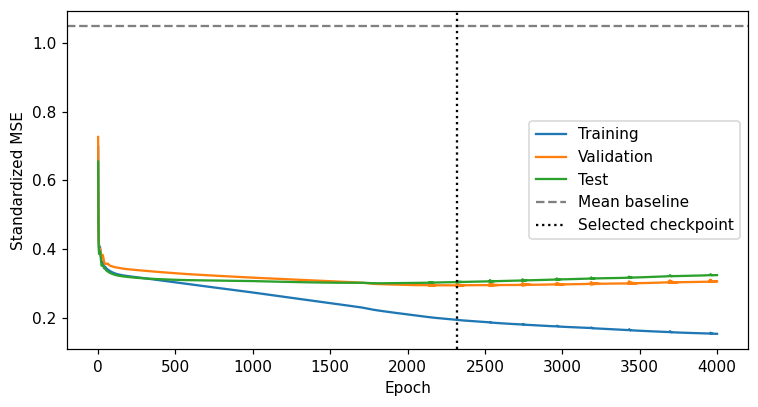

In [8]:
epochs_axis = np.arange(1, len(point_history) + 1)
plt.figure(figsize=(7, 3.8))
plt.plot(epochs_axis, point_history[:, 0], label="Training")
plt.plot(epochs_axis, point_history[:, 1], label="Validation")
plt.plot(epochs_axis, point_history[:, 2], label="Test")
plt.axhline(validation_baseline, color="gray", ls="--", label="Mean baseline")
plt.axvline(point_epoch, color="black", ls=":", label="Selected checkpoint")
plt.xlabel("Epoch")
plt.ylabel("Standardized MSE")
plt.legend()
plt.tight_layout()
plt.show()

Test RMSE: 2.517 x 10^-6 A^-2


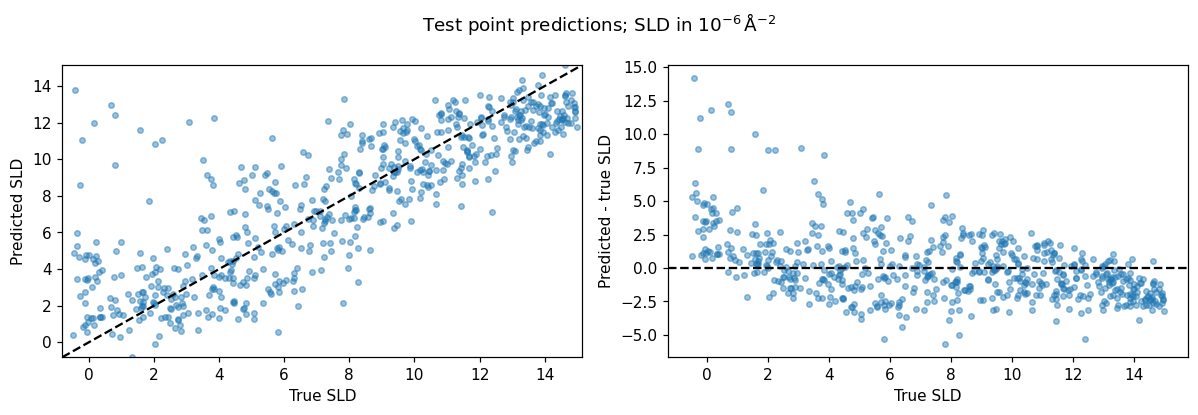

In [9]:
with torch.no_grad():
    point_val_scaled = point_model(xvl).numpy().ravel()
    point_test_scaled = point_model(xte).numpy().ravel()  

val_true = y[val_idx, 0]
point_val = physical_sld(point_val_scaled)
point_residual = point_val - val_true
point_val_rmse = np.sqrt(np.mean(point_residual**2))
test_true = y[test_idx, 0]  
point_test = physical_sld(point_test_scaled)  
point_test_rmse = np.sqrt(np.mean((point_test - test_true)**2))  
print(f"Test RMSE: {point_test_rmse / SLD_UNIT:.3f} x 10^-6 A^-2") 

def plot_predictions(true, predicted, title):
    truth = np.asarray(true) / SLD_UNIT
    prediction = np.asarray(predicted) / SLD_UNIT
    limits = [min(truth.min(), prediction.min()), max(truth.max(), prediction.max())]
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    axes[0].scatter(truth, prediction, s=13, alpha=0.45)
    axes[0].plot(limits, limits, "k--")
    axes[0].set(xlim=limits, ylim=limits, xlabel="True SLD", ylabel="Predicted SLD")
    axes[1].scatter(truth, prediction - truth, s=13, alpha=0.45)
    axes[1].axhline(0, color="black", ls="--")
    axes[1].set(xlabel="True SLD", ylabel="Predicted - true SLD")
    fig.suptitle(title + r"; SLD in $10^{-6}\,\mathrm{\AA}^{-2}$")
    plt.tight_layout()
    plt.show()

plot_predictions(test_true, point_test, "Test point predictions")  

**Explain**

1. Does the network improve on predicting the same mean for every curve?
2. Are the errors equally large across the SLD range? Describe the low-SLD region.
3. Is the predicted SLD always a plausible unique solution to the inverse problem?

We observe useful learning, alongside scatter and systematic errors. These
errors can involve limited training data, network approximation, inverse
ambiguity, and any noise present in the supplied curves. This plot alone
cannot separate those causes.

**Instructor answers — interpreting the point predictions**

1. **Improvement over the mean predictor:** yes, the curve contains learnable
   information. During checkpoint selection, the model reaches validation MSE
   about **0.294**, compared with **1.047** for the training-mean predictor on
   that same validation partition. This is a validation comparison, not an
   independent performance estimate. The separate test evaluation gives MSE
   **0.305** and RMSE about **$2.517\times10^{-6}\,\mathrm{A}^{-2}$**.
2. **Dependence on SLD:** the saved test plot shows substantial scatter and several
   large positive residuals at low true SLD: some low-SLD curves receive much
   larger predicted SLD values. At the high-SLD end, predictions tend to fall
   below the diagonal. Residuals vary across the true-SLD range. This pattern
   alone cannot distinguish model bias from variability remaining around the
   correct conditional mean.
4. **Physical plausibility and uniqueness:** neither is guaranteed by a scalar
   prediction. The conditional mean can average distinct alternatives, and the
   linear output does not enforce physical parameter bounds. Even a value inside
   the simulated SLD range does not establish a unique compatible structure.
   Assessing that requires the other parameters, a physical forward model, and
   appropriate measurement and prior information.

## Exercise 2.2: overfitting, epochs, and training-set size

More training can reduce training error without improving predictions on
new examples. We now deliberately use **no weight decay**.

**Predict:** compare 100 training curves with all 1901. Which training loss
will become smaller? Which model should generalize better? Will their best
epochs be the same?

**Run:** compare nested random subsets of 100, 500, and all training curves.
Validation examples remain fixed. Each subset supplies its own scaling
statistics, so compare losses converted to the same physical units.
One full-batch epoch is one optimizer update for each subset.

**Instructor answers — predicting the effect of training-set size**

1. **Training loss:** the 100-example model is expected to achieve the smaller
   training error because the same network has far fewer examples to fit. The
   saved final-training-error plot shows a nearly perfect fit to that subset,
   while the full training set retains a larger training RMSE.
2. **Generalization:** the model trained on all 1901 examples is expected to learn
   a more representative mapping. In the displayed experiment it has the best
   selected validation result, despite its larger final training error.
3. **Selected epoch:** the epochs need not be the same. With less data, fitting
   training-specific details can begin earlier; the displayed reference curves
   select approximately 53, 256, and 577 epochs for 100, 500, and 1901 examples.
   This ordering is an observation here, not a universal rule. One epoch is one
   full-batch optimizer update in every case, rather than an equal amount of
   computation or an equal number of processed examples.

In [10]:
subset_order = np.random.default_rng(7).permutation(train_idx)
training_sizes = [100, 500, len(train_idx)]
size_results = []

for n_samples in training_sizes:
    subset_idx = subset_order[:n_samples]
    subset_x_scaler = StandardScaler().fit(x[subset_idx])
    subset_y_scaler = StandardScaler().fit(y[subset_idx])
    subset_xtr = to_tensor(subset_x_scaler.transform(x[subset_idx]))
    subset_ytr = to_tensor(subset_y_scaler.transform(y[subset_idx]))
    subset_xvl = to_tensor(subset_x_scaler.transform(x[val_idx]))
    subset_yvl = to_tensor(subset_y_scaler.transform(y[val_idx]))
    subset_xte = to_tensor(subset_x_scaler.transform(x[test_idx]))  
    subset_yte = to_tensor(subset_y_scaler.transform(y[test_idx]))  

    subset_model = make_network(hidden_size=64, seed=1)
    history, selected_epoch, seconds = train_mse(
        subset_model, subset_xtr, subset_ytr, subset_xvl, subset_yvl,
        test_inputs=subset_xte, test_targets=subset_yte,  
#        epochs=4000, learning_rate=1e-3, weight_decay=0.0
        epochs=4000, learning_rate=5e-4, weight_decay=0.0
    )
    physical_rmse = np.sqrt(history) * subset_y_scaler.scale_[0] / SLD_UNIT
    size_results.append({"n": n_samples, "epoch": selected_epoch,
                         "rmse": physical_rmse, "seconds": seconds})
    print(f"N={n_samples:4d}: best epoch={selected_epoch:4d}, "
          f"validation RMSE={physical_rmse[selected_epoch - 1, 1]:.3f} "
          f"(10^-6 A^-2), time={seconds:.1f} s")
    print(f"  Test RMSE at selected epoch: {physical_rmse[selected_epoch - 1, 2]:.3f} (10^-6 A^-2)")  

100%|██████████████████████████████████████████████████████████████████████████████| 4000/4000 [00:10<00:00, 398.05it/s]


N= 100: best epoch=  53, validation RMSE=2.698 (10^-6 A^-2), time=10.1 s
  Test RMSE at selected epoch: 2.693 (10^-6 A^-2)


100%|██████████████████████████████████████████████████████████████████████████████| 4000/4000 [00:19<00:00, 204.81it/s]


N= 500: best epoch= 256, validation RMSE=2.680 (10^-6 A^-2), time=19.5 s
  Test RMSE at selected epoch: 2.576 (10^-6 A^-2)


100%|██████████████████████████████████████████████████████████████████████████████| 4000/4000 [00:38<00:00, 104.70it/s]

...

 97%|█████████▋| 1462/1500 [00:07<00:00, 188.66it/s]

 99%|█████████▊| 1481/1500 [00:07<00:00, 188.19it/s]

100%|██████████| 1500/1500 [00:07<00:00, 186.53it/s]

100%|██████████| 1500/1500 [00:07<00:00, 189.93it/s]

N=1901: best epoch= 394, validation RMSE=2.564 (10^-6 A^-2), time=7.9 s
  Test RMSE at selected epoch: 2.599 (10^-6 A^-2)


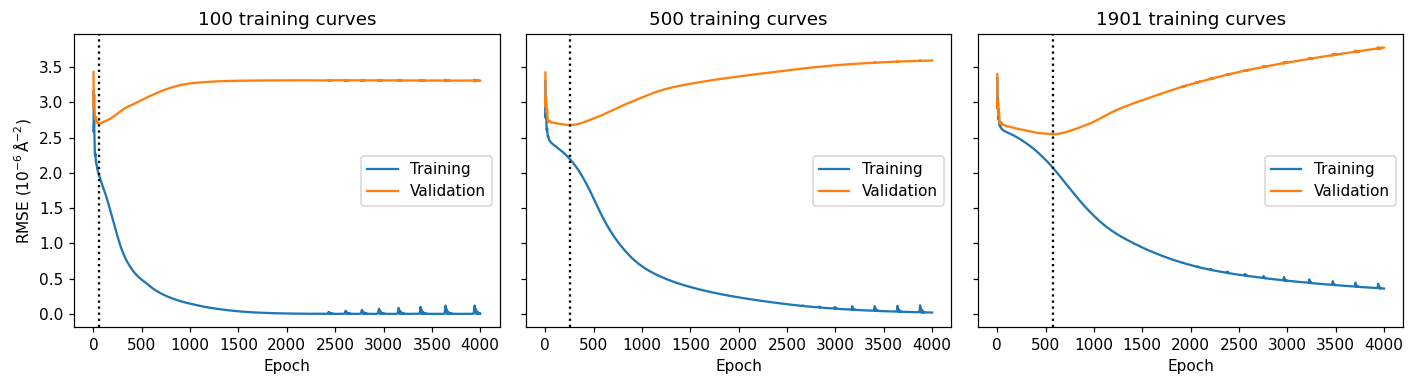

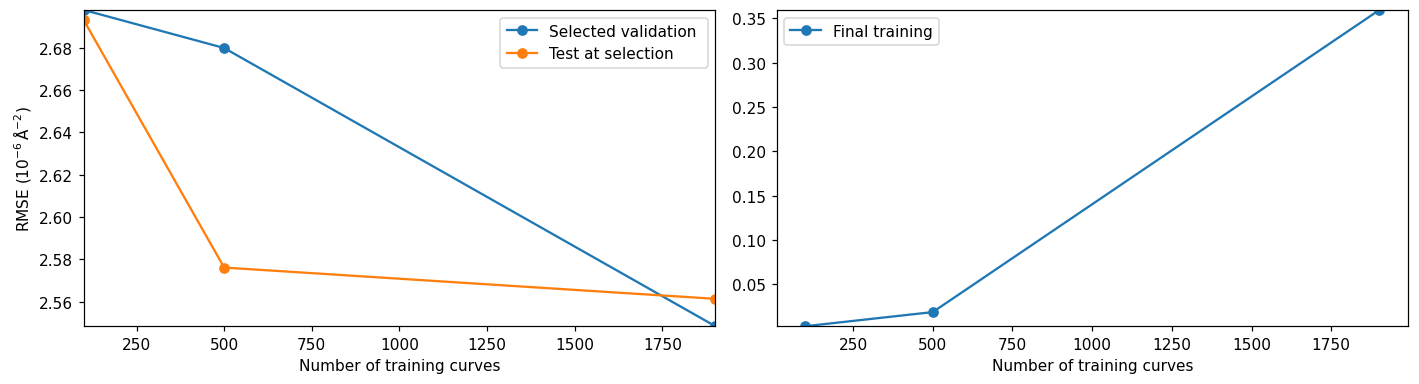

In [11]:
fig, axes = plt.subplots(1, len(size_results), figsize=(13, 3.6), sharey=True)
for ax, result in zip(axes, size_results):
    axis_epochs = np.arange(1, len(result["rmse"]) + 1)
    ax.plot(axis_epochs, result["rmse"][:, 0], label="Training")
    ax.plot(axis_epochs, result["rmse"][:, 1], label="Validation")
    ax.axvline(result["epoch"], color="black", ls=":")
    ax.set(title=f"{result['n']} training curves", xlabel="Epoch")
    ax.legend()
axes[0].set_ylabel(r"RMSE ($10^{-6}\,\mathrm{\AA}^{-2}$)")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1,2, figsize=(13, 3.6), sharey=False)  #x
# plt.figure(figsize=(6, 3.5))
axes[0].plot([r["n"] for r in size_results],
         [r["rmse"][r["epoch"] - 1, 1] for r in size_results], "o-", label="Selected validation ")
axes[0].plot([r["n"] for r in size_results],
         [r["rmse"][r["epoch"] - 1, 2] for r in size_results], "o-", label="Test at selection")
axes[0].set_xlabel("Number of training curves")
axes[0].set_ylabel(r"RMSE ($10^{-6}\,\mathrm{\AA}^{-2}$)")
axes[0].autoscale(tight=True)
axes[0].legend()

axes[1].plot([r["n"] for r in size_results],
         [r["rmse"][-1, 0] for r in size_results], "o-", label="Final training")
axes[1].set_xlabel("Number of training curves")
axes[1].autoscale(axis="y", tight=True)  
axes[1].legend()


fig.tight_layout()
plt.show()

**Explain**

1. Find an epoch range in which training error falls while validation error rises.
2. Does a nearly perfect fit to 100 examples give the best validation result?
3. How does training size affect the selected epoch and validation error?
4. Why should we select a checkpoint using validation rather than training loss?

A learning curve need not decrease at every sample count: particular samples,
initialization, and optimization matter. Here each subset is one illustrative
run, not an estimate with repeat-run error bars.

**Optional extension:** rerun this experiment with weight decay `1e-2`.
Compare validation performance as well as the train/validation gap; a smaller
gap alone can also indicate underfitting. Keep the test set out of this choice.

**Instructor answers — overfitting and checkpoint selection**

1. **An overfitting interval:** in the 100-example panel, roughly epochs 200–1000
   show training RMSE falling while validation RMSE rises. In the full-data panel,
   the same divergence is visible, for example, around epochs 1000–3000. The
   important observation is the opposing trends, rather than an exact boundary.
2. **A nearly perfect fit is not the best validation model:** the 100-example
   model approaches zero training error but has a worse selected validation RMSE
   than the full-data model. Memorizing the subset does not supply the information
   needed to predict new curves accurately.
3. **Training size and selected performance:** in the run represented by the
   displayed figures, the results are:

   | Training curves | Selected epoch | Validation RMSE at selection | Test RMSE at selection |
   |---:|---:|---:|---:|
   | 100 | 53 | 2.698 | 2.693 |
   | 500 | 256 | 2.680 | 2.576 |
   | 1901 | 577 | 2.548 | 2.561 |

   RMSE values are in $10^{-6}\,\mathrm{A}^{-2}$. The larger training sets
   improve the selected validation result in this experiment. The test column
   evaluates those validation-selected checkpoints; it is not used to select
   them. Other saved run outputs have somewhat different epochs, so use the
   table as the reference for the displayed figures, rather than a universal
   numerical result.
4. **Why validation selects the checkpoint:** training loss measures performance
   on examples already used to adjust the weights and can favour memorization.
   Validation measures predictions on examples excluded from weight updates.
   Repeatedly selecting its minimum still makes that minimum optimistic as a
   performance estimate; the test partition supplies the separate evaluation.

**Optional weight-decay comparison:** adding weight decay may limit the growth
of weights and reduce overfitting, often leaving a larger training error. A
smaller train/validation gap is useful only when validation performance is also
acceptable; both losses can be poor under underfitting. The current notebook
does not show a separate saved run of this optional comparison, so no measured
improvement is claimed. Use validation to assess it, without selecting settings
from the test curves.

## Exercise 2.3: predict a Gaussian mean and variance

Our point model reports one SLD, although some curves are much harder to
interpret than others. We extend the network to describe a **Gaussian
conditional distribution** with a mean $\mu(x)$ and variance $\sigma^2(x)$.

This is an assumption about the possible SLD values given a curve, within
our simulation population. The same framework can use other conditional 
distributions, such as the familiar Poisson distribution for count data.
However, a single Gaussian cannot describe every possible conditional 
distribution, especially when several separated solutions are compatible 
with the same curve. 

The variance output is intended to estimate data uncertainty (aleatoric uncertainty), but may also absorb model error.

We train both outputs using Gaussian negative log-likelihood (NLL):

$$\mathcal L=\frac{1}{2N}\sum_i\left[
\log\sigma_i^2 + \frac{(y_i-\mu_i)^2}{\sigma_i^2}\right]+\text{constant}.$$

A confident mistake incurs a large cost through the residual term; making every variance large incurs a cost through the logarithm.
The network predicts an unconstrained value $s_i$, which is transformed into a positive variance using
$
\sigma_i^2=\operatorname{softplus}(s_i)+10^{-4}
=\log(1+\exp(s_i))+10^{-4}.
$
The small floor $10^{-4}$ prevents numerically problematic near-zero variances. It is expressed in standardized target variance units (squared standardized SLD units), not instrumental reflectivity units.

NLL can be negative because a probability density can exceed one. Its
absolute value also depends on target units; compare scores on the same scale.

The implementation omits the additive Gaussian constant, $\tfrac12\log(2\pi)$, which shifts the reported loss values without affecting training.

**Predict:** should every curve receive the same uncertainty? Would very wide
intervals necessarily be useful?

**Instructor answers — predicting uncertainty**

1. **Equal uncertainty for every curve:** there is no reason to assume equal
   conditional spread. Curves may constrain SLD differently because of ambiguity
   involving the other structural parameters and any noise in the simulations.
   The variance output lets the network estimate an input-dependent spread.
   These estimates can also be affected by errors in the learned mapping.
2. **Very wide intervals:** they can include many targets while giving little
   useful information about SLD. High coverage alone is insufficient: compare
   coverage with interval widths. Gaussian NLL discourages both confident misses
   and indiscriminately large variances through its residual and logarithmic
   terms. A useful distribution balances the two.

In [12]:
def gaussian_outputs(raw_output):
    mean = raw_output[:, :1]
    variance = torch.nn.functional.softplus(raw_output[:, 1:2]) + 1e-4
    return mean, variance

def gaussian_nll(raw_output, target):
    mean, variance = gaussian_outputs(raw_output)
    assert mean.shape == target.shape
    # The additive 0.5*log(2*pi) does not affect training or selection.
    return 0.5 * (torch.log(variance) + (target - mean)**2 / variance).mean()

def train_gaussian(model, train_inputs, train_targets, val_inputs, val_targets,
                   epochs=1500, learning_rate=2e-4, weight_decay=1e-2,  
                   test_inputs=None, test_targets=None):  
    optimizer = torch.optim.Adam(
        model.parameters(), lr=learning_rate, weight_decay=weight_decay
    )
    # Columns: training, validation, and test (when supplied).  
    evaluation_sets = [(train_inputs, train_targets), (val_inputs, val_targets)]  
    if test_inputs is not None:  
        evaluation_sets.append((test_inputs, test_targets))  
    history = np.empty((epochs, len(evaluation_sets)))  
    best_loss = float("inf")
    start = perf_counter()
    for epoch in tqdm(range(epochs)):
        model.train()
        optimizer.zero_grad()
        loss = gaussian_nll(model(train_inputs), train_targets)
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            for j, (inputs, targets) in enumerate(evaluation_sets):  
                history[epoch, j] = gaussian_nll(model(inputs), targets).item()  
        if history[epoch, 1] < best_loss:
            best_loss = history[epoch, 1]
            selected_epoch = epoch + 1
            best_state = deepcopy(model.state_dict())

    assert np.isfinite(history).all()
    model.load_state_dict(best_state)
    model.eval()
    return history, selected_epoch, perf_counter() - start

100%|███████████████████████████████████████████████████████████████████████████████| 1500/1500 [00:15<00:00, 97.31it/s]


Selected epoch: 388; training time: 15.4 s
Test NLL at selected epoch (constant omitted): -0.127


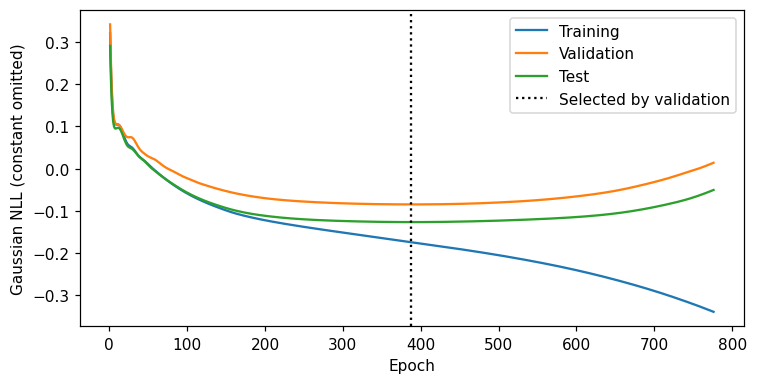

In [13]:
gaussian_model = make_network(hidden_size=64, outputs=2, seed=1)
gaussian_history, gaussian_epoch, gaussian_seconds = train_gaussian(
    gaussian_model, xtr, ytr, xvl, yvl, test_inputs=xte, test_targets=yte  
)
print(f"Selected epoch: {gaussian_epoch}; training time: {gaussian_seconds:.1f} s")
gaussian_test_nll = gaussian_history[gaussian_epoch - 1, 2] 
print(f"Test NLL at selected epoch (constant omitted): {gaussian_test_nll:.3f}")  

# Show the learning curves around the validation-selected checkpoint.  
plot_epochs = min(2*gaussian_epoch, len(gaussian_history))  
plt.figure(figsize=(7, 3.6))  
for j, label in enumerate(["Training", "Validation", "Test"]):  
    plt.plot(np.arange(1, plot_epochs + 1), gaussian_history[:plot_epochs, j], label=label)  
plt.axvline(gaussian_epoch, color="black", ls=":", label="Selected by validation")  
plt.xlabel("Epoch")  
plt.ylabel("Gaussian NLL (constant omitted)")  
plt.legend()  
plt.tight_layout()
plt.show()

### Inspect the predicted mean and variance  

For three test curves, compare the known target with the network's mean $\mu$, variance $\sigma^2$, and standard deviation $\sigma=\sqrt{\sigma^2}$.  
The Gaussian plots mark the target and shade $\mu\pm\sigma$.  

We select examples with low, middle, and high predicted uncertainty, without selecting them by their prediction errors. Keep these test  
examples for the next exercise, where we assess ensemble disagreement as a limited proxy for epistemic uncertainty. 

The predicted spread is intended to estimate conditional variability, interpreted here as data uncertainty (aleatoric uncertainty). It may also include errors in the learned mapping. It can include ambiguity involving the other structural parameters and is not simply measurement noise.

For a Gaussian, about 68% of its probability lies within $\mu\pm\sigma$ and 95% within $\mu\pm1.96\sigma$. The final check counts how often the  
known test targets fall inside these intervals.  

In [14]:
def predict_gaussian(model, inputs):
    model.eval()
    with torch.no_grad():
        mean_scaled, variance_scaled = gaussian_outputs(model(inputs))
    mean = physical_sld(mean_scaled.numpy().ravel())
    sigma = np.sqrt(variance_scaled.numpy().ravel()) * y_scaler.scale_[0]
    assert np.isfinite(mean).all() and np.isfinite(sigma).all() and (sigma > 0).all()
    return mean, sigma

# One prediction pass using the restored checkpoint; the NLL is already in history.  
gaussian_test, sigma_test = predict_gaussian(gaussian_model, xte)  
variance_test = sigma_test**2 
uncertainty_example_idx = np.argsort(sigma_test)[  
    (np.array([0.1, 0.4, 0.9]) * (len(test_idx)-1)).astype(int)  
]  

print("SLD values in 10^-6 A^-2; variance in (10^-6 A^-2)^2.")  
print(f"{'Curve':>6} {'Target':>9} {'Mean':>9} {'Variance':>11} {'Std dev':>9}")  
for i in uncertainty_example_idx:  
    print(f"{test_idx[i]:6d} {test_true[i]/SLD_UNIT:9.3f} "  
          f"{gaussian_test[i]/SLD_UNIT:9.3f} {variance_test[i]/SLD_UNIT**2:11.3f} "  
          f"{sigma_test[i]/SLD_UNIT:9.3f}")  

SLD values in 10^-6 A^-2; variance in (10^-6 A^-2)^2.
 Curve    Target      Mean    Variance   Std dev
   674     2.657     2.532       2.366     1.538
   250     5.113     9.241       6.336     2.517
  2287    11.261    10.394       9.046     3.008


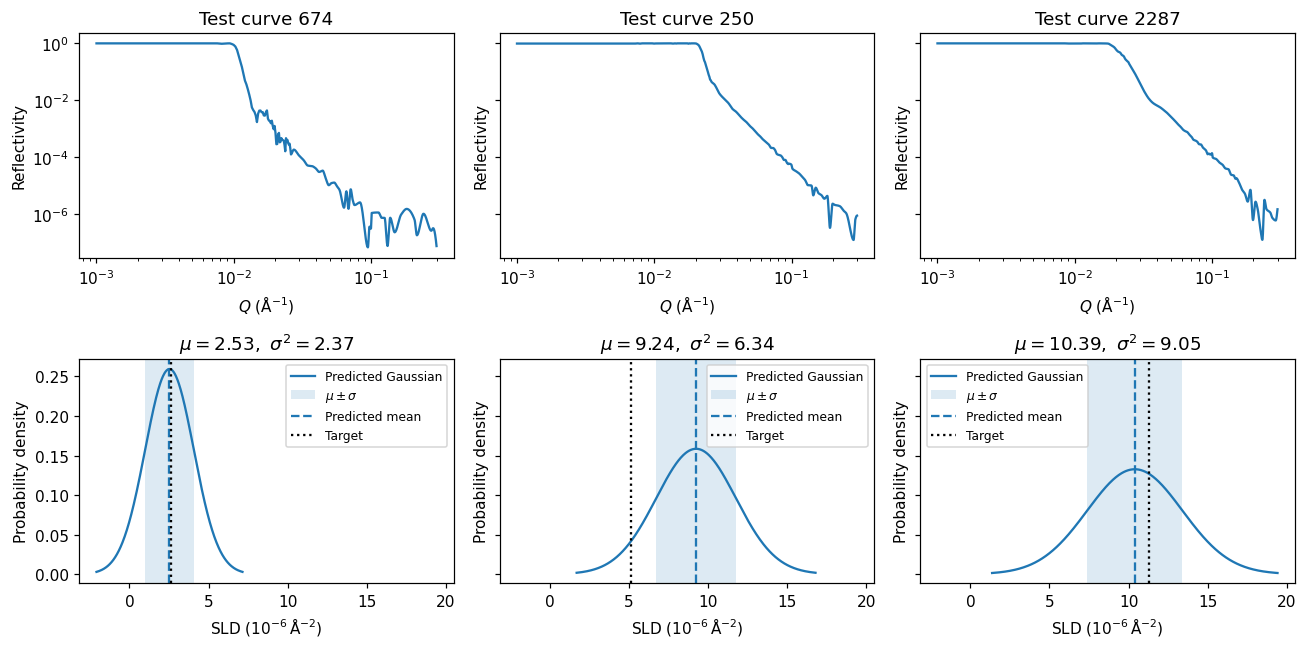

In [15]:
def plot_uncertainty_examples(indices, mean, variance, label="Predicted"):  
    # Return the axes so the next exercise can add uncertainty components.  
    fig, axes = plt.subplots(2, len(indices), figsize=(12, 6), squeeze=False, sharex="row", sharey="row")  
    for column, i in enumerate(indices):  
        axes[0, column].loglog(q, X[test_idx[i]])  
        axes[0, column].set(title=f"Test curve {test_idx[i]}", xlabel=r"$Q$ ($\mathrm{\AA}^{-1}$)",  
                            ylabel="Reflectivity")  

        mu = mean[i] / SLD_UNIT  
        variance_display = variance[i] / SLD_UNIT**2  
        sigma = np.sqrt(variance_display)  
        target = test_true[i] / SLD_UNIT  
        grid = np.linspace(min(mu-3*sigma, target-sigma),  
                           max(mu+3*sigma, target+sigma), 400)  
        density = np.exp(-0.5*((grid-mu)/sigma)**2) / (sigma*np.sqrt(2*np.pi))  
        ax = axes[1, column]  
        ax.plot(grid, density, label=f"{label} Gaussian")  
        ax.axvspan(mu-sigma, mu+sigma, alpha=0.15, label=r"$\mu\pm\sigma$")  
        ax.axvline(mu, color="C0", ls="--", label="Predicted mean")  
        ax.axvline(target, color="black", ls=":", label="Target")  
        ax.set(title=rf"$\mu={mu:.2f},\ \sigma^2={variance_display:.2f}$",  
               xlabel=r"SLD ($10^{-6}\,\mathrm{\AA}^{-2}$)", ylabel="Probability density")  
        ax.legend(fontsize=8)  
    fig.tight_layout()  
    return fig, axes  

example_fig, example_axes = plot_uncertainty_examples(  
    uncertainty_example_idx, gaussian_test, variance_test  
)  #+
plt.show()

In [16]:
# One collective check: how often does the target lie inside the interval?  
absolute_error = np.abs(test_true - gaussian_test)  
coverage68 = np.mean(absolute_error <= sigma_test)  
coverage95 = np.mean(absolute_error <= 1.96*sigma_test)  
print(f"Test coverage: mu +/- sigma: {coverage68:.1%} (nominal 68%); "  
      f"mu +/- 1.96 sigma: {coverage95:.1%} (nominal 95%).")  

Test coverage: mu +/- sigma: 69.1% (nominal 68%); mu +/- 1.96 sigma: 95.6% (nominal 95%).


**Instructor answer — how often the target is inside the interval**

The saved test results give **69.1%** inside $\mu\pm\sigma$ and **95.6%** inside
$\mu\pm1.96\sigma$, close to the Gaussian reference probabilities of about
68.3% and 95.0%. This is a collective coverage check on the 634 test curves.
It supports the overall interval frequencies at these two levels; it does not
establish that each curve's variance estimate is correct or that the full
conditional distribution has been learned accurately everywhere.

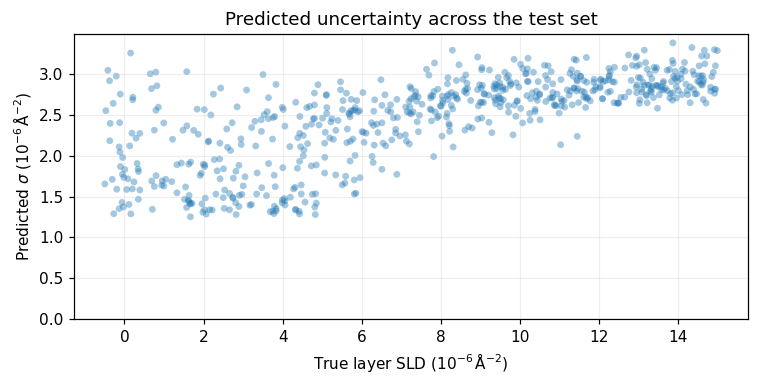

In [17]:
# dependence of predicted uncertainty on the SLD value
plt.figure(figsize=(7, 3.6))
plt.scatter(test_true / SLD_UNIT, sigma_test / SLD_UNIT,  
            s=20, alpha=0.4, edgecolors="none") 
plt.xlabel(r"True layer SLD ($10^{-6}\,\mathrm{\AA}^{-2}$)")  
plt.ylabel(r"Predicted $\sigma$ ($10^{-6}\,\mathrm{\AA}^{-2}$)")  
plt.title("Predicted uncertainty across the test set")  
plt.ylim(bottom=0)  
plt.grid(alpha=0.2)  
plt.tight_layout()
plt.show()

**Explain**

1. Compare the three examples: how do the predicted mean and Gaussian width vary?  
2. How far is each known target from the predicted mean, relative to $\sigma$?  
3. Across all test curves, how close is interval coverage to the nominal 68% and 95%?  

A single curve gives one known SLD, not a known variance. Coverage checks  
the intervals collectively; it does not prove that every individual  
uncertainty estimate is correct. Epistemic uncertainty has not yet been added.  

**Instructor answers — the three Gaussian predictions**

1. **Means and widths:** the selected examples have increasing predicted means
   and standard deviations:

   | Test curve | Target | Predicted mean | Predicted standard deviation | $|y-\mu|/\sigma$ |
   |---:|---:|---:|---:|---:|
   | 674 | 2.657 | 2.532 | 1.538 | 0.08 |
   | 250 | 5.113 | 9.241 | 2.517 | 1.64 |
   | 2287 | 11.261 | 10.394 | 3.008 | 0.29 |

   SLD and standard deviations are in $10^{-6}\,\mathrm{A}^{-2}$; the final
   column is dimensionless. Curve 674 has the narrowest predicted distribution,
   and curve 2287 the broadest. This ordering describes the model's predictions,
   without establishing their accuracy as uncertainty estimates.
2. **Target distance relative to width:** curves 674 and 2287 lie well inside one
   predicted standard deviation; curve 250 lies outside one but inside 1.96
   standard deviations. An individual error can be smaller or larger than
   $\sigma$: a standard deviation describes spread, not a minimum error or a
   bound. One close target does not demonstrate that its variance was too large.
3. **Collective coverage:** 69.1% and 95.6% are close to the two nominal Gaussian
   probabilities. The three selected illustrations cannot establish calibration;
   the coverage calculation uses all test curves. In the added SLD scatter plot,
   predicted widths generally increase toward high true SLD. That descriptive
   trend alone does not show whether those widths correctly describe the errors.

## Exercise 2.4: ensemble disagreement as a proxy for epistemic uncertainty

The previous exercise used one network to predict a Gaussian mean and variance.
Now train an **ensemble of five networks**, each with the same architecture,
training data, and settings, but different random initial weights. Each member's
checkpoint is selected using validation NLL. Test labels only supply evaluation.

For one curve, member $m$ predicts $\mu_m$ and $\sigma_m^2$. We combine them as

$$\bar\mu=\frac{1}{M}\sum_m\mu_m,$$

$$v_{\mathrm{within}}=\frac{1}{M}\sum_m\sigma_m^2,
\qquad v_{\mathrm{between}}=\frac{1}{M}\sum_m(\mu_m-\bar\mu)^2,$$

$$v_{\mathrm{mixture}}=v_{\mathrm{within}}+v_{\mathrm{between}}.$$

- **Within-member predicted variance:** the average variance predicted within the members.
- **Between-member mean variance:** disagreement between their predicted means.
- **Mixture variance:** the variance of the equally weighted mixture of their predictions.

The within-member term is intended to estimate aleatoric uncertainty but may also
absorb model error. Between-member disagreement is a limited proxy for epistemic
uncertainty and can miss errors shared by all members.

We add **variances**, then take square roots to report standard deviations in
SLD units. The within-member standard deviation is
$\sqrt{\operatorname{mean}_m\sigma_m^2}$, rather than the mean of the standard
deviations. Use `ddof=0` because each of our five networks contributes equally: we divide the sum of squared deviations by five.

**Predict:** will the networks agree on all three examples? Can all five agree
on a mean that is far from the true SLD?

**Instructor answers — predicting ensemble agreement**

1. **Agreement on the three curves:** different initializations need not produce
   identical means or variances. In this full-data example, however, their
   distributions nearly overlap and their mean predictions differ only slightly.
2. **Agreement far from the target:** yes. For the middle example, the ensemble
   mean is about 9.284 while the target is 5.113, despite a standard deviation
   across member means of only 0.037. The members share the training data,
   architecture, loss, and training procedure, so agreement does not ensure
   that their common prediction is close to an individual target. Different
   initial weights do not make their prediction errors independent.

In [18]:
# Reuse the seed-1 Gaussian model; train four additional independent members.
ensemble_seeds = [1, 2, 3, 4, 5]
ensemble_models = [gaussian_model]
ensemble_histories = [gaussian_history]  
ensemble_epochs = [gaussian_epoch]  
ensemble_training_seconds = gaussian_seconds
for seed in ensemble_seeds[1:]:
    member = make_network(hidden_size=64, outputs=2, seed=seed)
    history, selected_epoch, seconds = train_gaussian(  
        member, xtr, ytr, xvl, yvl, test_inputs=xte, test_targets=yte  
    )  #+
    ensemble_models.append(member)
    ensemble_histories.append(history)  
    ensemble_epochs.append(selected_epoch)  
    ensemble_training_seconds += seconds
    print(f"Seed {seed}: selected epoch {selected_epoch}; "  
          f"test NLL={history[selected_epoch-1, 2]:.3f} (constant omitted)")  
print(f"Total ensemble training time, including seed 1: {ensemble_training_seconds:.1f} s")

100%|██████████████████████████████████████████████████████████████████████████████| 1500/1500 [00:14<00:00, 101.08it/s]


Seed 2: selected epoch 465; test NLL=-0.128 (constant omitted)


100%|██████████████████████████████████████████████████████████████████████████████| 1500/1500 [00:14<00:00, 103.67it/s]


Seed 3: selected epoch 640; test NLL=-0.120 (constant omitted)


100%|██████████████████████████████████████████████████████████████████████████████| 1500/1500 [00:14<00:00, 103.54it/s]


...

 98%|█████████▊| 1464/1500 [00:14<00:00, 121.71it/s]

 98%|█████████▊| 1477/1500 [00:15<00:00, 118.35it/s]

 99%|█████████▉| 1489/1500 [00:15<00:00, 118.65it/s]

100%|██████████| 1500/1500 [00:15<00:00, 98.75it/s] 

Seed 5: selected epoch 425; test NLL=-0.122 (constant omitted)
Total ensemble training time, including seed 1: 74.8 s


### Compare the same three test curves

For the `uncertainty_example_idx` from the previous exercise, each thin grey curve below is one member's Gaussian prediction.
The thick blue curve is their **average density**, a Gaussian mixture. The vertical lines show the ensemble mean and the true SLD. Shared axes make widths comparable.

In the table, **Within**, **Between**, and **Mixture** are the square roots of the three variances above. Compare them with the actual absolute error for each example. One observed error need not equal a predicted standard deviation.

The mixture need not be Gaussian. Its total standard deviation describes spread. $\bar\mu\pm1.96\sigma_{\mathrm{total}}$ is not automatically a 95% mixture interval.

In [19]:
def ensemble_summary(means, variances):  
    mean = means.mean(axis=0)  
    aleatoric = variances.mean(axis=0)  
    epistemic = means.var(axis=0, ddof=0)  
    return mean, aleatoric, epistemic, aleatoric + epistemic  

predictions = [predict_gaussian(member, xte) for member in ensemble_models]  
member_test_means = np.stack([mean for mean, sigma in predictions])  
member_test_variances = np.stack([sigma**2 for mean, sigma in predictions])  
ensemble_test, aleatoric_test, epistemic_test, total_test = ensemble_summary(  
    member_test_means, member_test_variances  
)  

print("All values below are in 10^-6 A^-2; uncertainty columns are standard deviations.")  
print(f"{'Curve':>6} {'Target':>8} {'Mean':>8} {'Within':>8} {'Between':>8} {'Mixture':>8} {'|error|':>8}")  
for i in uncertainty_example_idx:  
    values = [test_true[i], ensemble_test[i], np.sqrt(aleatoric_test[i]),  
              np.sqrt(epistemic_test[i]), np.sqrt(total_test[i]),  
              abs(ensemble_test[i] - test_true[i])]  
    print(f"{test_idx[i]:6d}" + "".join(f"{value / SLD_UNIT:8.3f}" for value in values))  
print(f"Ensemble mean: test RMSE={np.sqrt(np.mean((ensemble_test-test_true)**2))/SLD_UNIT:.3f}")  

All values below are in 10^-6 A^-2; uncertainty columns are standard deviations.
 Curve   Target     Mean   Within  Between  Mixture  |error|
   674   2.657   2.363   1.528   0.132   1.534   0.294
   250   5.113   9.284   2.543   0.037   2.543   4.170
  2287  11.261  10.432   3.005   0.087   3.007   0.829
Ensemble mean: test RMSE=2.537


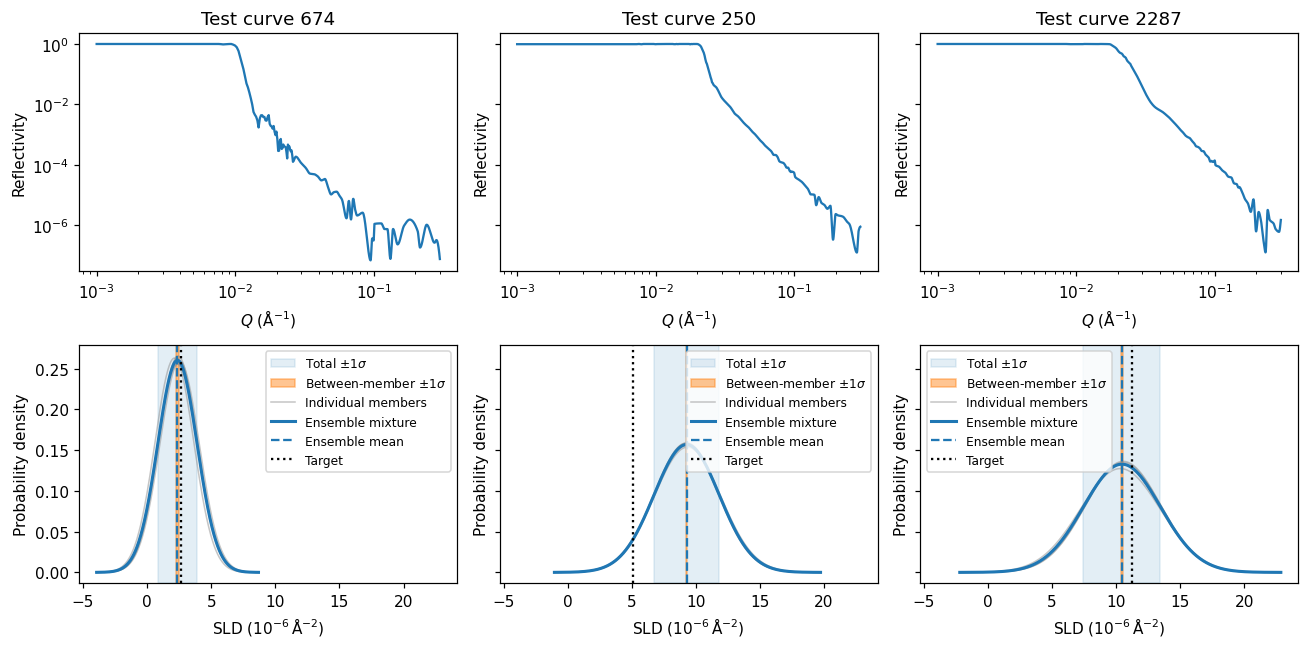

In [20]:
def plot_ensemble_examples(indices, means, variances):  
    # Physical predictions are converted to the same display units as Exercise 2.3.  
    mean, _, epistemic, total = ensemble_summary(means, variances)  
    mean = mean / SLD_UNIT  
    epistemic_std = np.sqrt(epistemic) / SLD_UNIT  
    total_std = np.sqrt(total) / SLD_UNIT  
    means = means / SLD_UNIT  
    sigmas = np.sqrt(variances) / SLD_UNIT  
    fig, axes = plt.subplots(2, len(indices), figsize=(12, 6), squeeze=False,  
                             sharex="row", sharey="row")  
    for column, i in enumerate(indices):  
        axes[0, column].loglog(q, X[test_idx[i]])  
        axes[0, column].set(title=f"Test curve {test_idx[i]}",  
                            xlabel=r"$Q$ ($\mathrm{\AA}^{-1}$)", ylabel="Reflectivity")  

        target = test_true[i] / SLD_UNIT  
        grid = np.linspace(min((means[:, i]-4*sigmas[:, i]).min(), target),  
                           max((means[:, i]+4*sigmas[:, i]).max(), target), 600)  
        densities = np.exp(-0.5*((grid[None, :]-means[:, i, None])  
                                / sigmas[:, i, None])**2)  
        densities /= sigmas[:, i, None] * np.sqrt(2*np.pi)  
        ax = axes[1, column]  
        # These bands show +/-1 standard deviation, without assigning a coverage probability.  
        ax.axvspan(mean[i]-total_std[i], mean[i]+total_std[i],  
                   color="C0", alpha=0.12, label=r"Total $\pm1\sigma$", zorder=0)  
        ax.axvspan(mean[i]-epistemic_std[i], mean[i]+epistemic_std[i],  
                   color="C1", alpha=0.45, label=r"Between-member $\pm1\sigma$", zorder=1)  
        for m, density in enumerate(densities):  
            ax.plot(grid, density, color="0.55", alpha=0.5, lw=1,  
                    label="Individual members" if m == 0 else None)  
        ax.plot(grid, densities.mean(axis=0), color="C0", lw=2, label="Ensemble mixture")  
        ax.axvline(mean[i], color="C0", ls="--", label="Ensemble mean")  
        ax.axvline(target, color="black", ls=":", label="Target")  
        ax.set(xlabel=r"SLD ($10^{-6}\,\mathrm{\AA}^{-2}$)", ylabel="Probability density")  
        ax.legend(fontsize=8)  
    fig.tight_layout()  
    return fig, axes  

ensemble_fig, ensemble_axes = plot_ensemble_examples(  
    uncertainty_example_idx, member_test_means, member_test_variances  
)  
plt.show()

In [21]:
# Coverage on all test curves using the total ensemble-mixture distribution.  
from scipy.stats import norm  

# A target is inside a central interval when its CDF lies between the tail probabilities.  
mixture_cdf_at_target = norm.cdf(  
    (test_true[None, :] - member_test_means) / np.sqrt(member_test_variances)  
).mean(axis=0)  
total_coverage68 = np.mean((mixture_cdf_at_target >= norm.cdf(-1))  
                           & (mixture_cdf_at_target <= norm.cdf(1)))  
total_coverage95 = np.mean((mixture_cdf_at_target >= norm.cdf(-1.96))  
                           & (mixture_cdf_at_target <= norm.cdf(1.96)))  
print(f"Test total-mixture coverage: 68% interval: {total_coverage68:.1%}; "  
      f"95% interval: {total_coverage95:.1%}.")  
print(f"Earlier single-network Gaussian interval coverage: 68% interval: {coverage68:.1%}; "  
      f"95% interval: {coverage95:.1%}.")  

Test total-mixture coverage: 68% interval: 68.9%; 95% interval: 95.3%.
Earlier single-network Gaussian interval coverage: 68% interval: 69.1%; 95% interval: 95.6%.


**Explain**

1. Do the member distributions nearly overlap? Compare the within-member and between-member
   standard deviations in the table. Which contributes more to the mixture spread?
2. For the middle example, how does the actual error compare with the disagreement?
   What does this tell us about treating agreement as evidence of correctness?
3. Would increasing the number of networks necessarily remove an error that all
   members share?

With the supplied full training set and reference settings, disagreement is small
relative to the predicted conditional spread. The mixture and individual curves
therefore look similar. This is an observation for this experiment, not evidence
that every source of epistemic uncertainty has been captured. Member means are
not posterior samples of the physical SLD.

**Instructor answers — interpreting the ensemble**

1. **Overlap and contributions:** yes, the full-data member distributions nearly
   overlap. For curves 674, 250, and 2287, the within-member standard
   deviations are 1.528, 2.543, and 3.005, while the between-member standard
   deviations are only 0.132, 0.037, and 0.087, respectively. Consequently, the
   within-member predicted variance dominates the mixture variance and its total standard
   deviations change very little. The components add as **variances**, rather
   than standard deviations; the gap between the shaded band widths is not
   a within-member standard deviation. This does not establish that genuine aleatoric
   uncertainty dominates all actual uncertainty.
2. **Middle example:** its absolute error, 4.170, is much larger than the
   disagreement, 0.037. Agreement therefore does not guarantee a small actual
   error. The error is about 1.64 total standard deviations, which is plausible
   under the nearly Gaussian predictive distribution. This single example
   establishes neither a systematic bias nor incorrect predictive coverage.
3. **More networks:** averaging more members can stabilize the estimate and
   reduce some effects of differing predictions. It does not necessarily remove
   a limitation or bias shared by every member, or remove conditional target
   variability. Increasing the number of seeds alone is not a guarantee of
   improved accuracy or calibrated uncertainty.

The two variance components describe the constructed ensemble distribution.
Identifying them with separate physical uncertainty sources remains approximate:
the predicted variances can absorb model errors, and the trained networks are
not established samples from a posterior over models. The total standard
deviation is a predicted spread, not the observed error of an individual curve.

The total-mixture coverage is **68.9% / 95.3%**, similar to the single network's
**69.1% / 95.6%**. The coverage cell uses central mixture-probability intervals;
the figure's shaded bands show $\bar\mu\pm1$ standard deviation and are not
automatically 68% intervals for an arbitrary mixture. Coverage need not increase
relative to the first network, because ensembling changes the predicted centre
and component distributions as well as adding disagreement.

### Optional: does less training data increase disagreement?

Set `run_small_ensemble = True` to train five new networks using only 100 training
curves. The scalers are fitted on that subset; validation still selects checkpoints.
Evaluate on the **same test partition and the same three example curves**.

The table compares the mean between-member standard deviation across the test
curves, used as a limited proxy for epistemic uncertainty.
The figure repeats the member and mixture distributions for the three examples.
This controlled comparison may make disagreement more visible; an increase is an
empirical observation rather than a guaranteed property of small ensembles.

**Instructor answer — the optional smaller-data ensemble**

With 100 training examples, disagreement is approximately 4.7 times larger.

Fewer examples constrain the learned mapping less strongly, allowing different initializations to produce more different predictions. This illustrates how additional representative training data can reduce one source of epistemic uncertainty.

The underlying conditional variability for a given test curve has not changed. What changes is how well the networks learn the mapping and how much their predictions disagree. Disagreement remains a limited proxy: all members can still share the same error, and an increase need not occur for every individual curve or every training run.

100%|██████████████████████████████████████████████████████████████████████████████| 1500/1500 [00:04<00:00, 304.39it/s]


100 curves, seed 1: selected epoch 86; test NLL=0.018 (subset-standardized units)


100%|██████████████████████████████████████████████████████████████████████████████| 1500/1500 [00:04<00:00, 313.64it/s]


100 curves, seed 2: selected epoch 71; test NLL=-0.014 (subset-standardized units)


100%|██████████████████████████████████████████████████████████████████████████████| 1500/1500 [00:04<00:00, 305.60it/s]


100 curves, seed 3: selected epoch 138; test NLL=-0.014 (subset-standardized units)


100%|██████████████████████████████████████████████████████████████████████████████| 1500/1500 [00:04<00:00, 307.97it/s]


100 curves, seed 4: selected epoch 84; test NLL=0.017 (subset-standardized units)


100%|██████████████████████████████████████████████████████████████████████████████| 1500/1500 [00:05<00:00, 284.58it/s]


100 curves, seed 5: selected epoch 101; test NLL=0.057 (subset-standardized units)
Mean between-member standard deviation (limited epistemic proxy) over the same test curves (10^-6 A^-2):
  1901 training curves: 0.073
  100 training curves:  0.340
Additional training time: 24.8 s


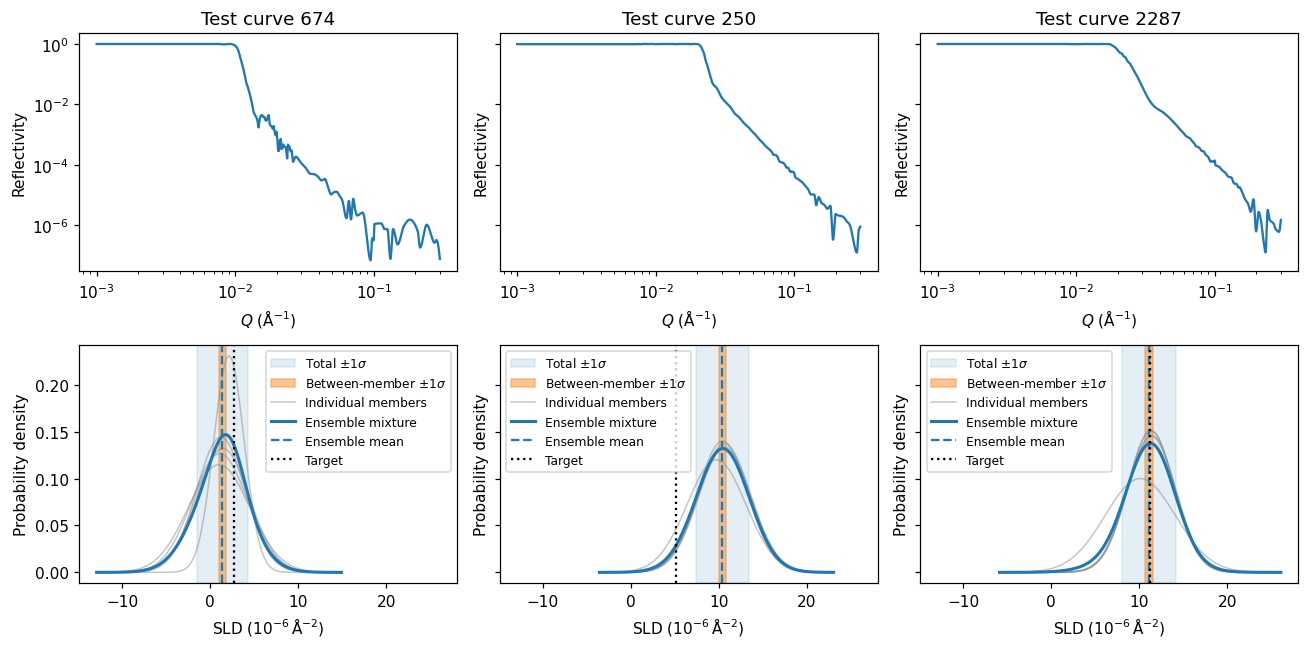

In [22]:
run_small_ensemble = True
small_ensemble_seconds = 0.0

if run_small_ensemble:
    small_idx = subset_order[:100]
    small_x_scaler = StandardScaler().fit(x[small_idx])
    small_y_scaler = StandardScaler().fit(y[small_idx])
    small_xtr = to_tensor(small_x_scaler.transform(x[small_idx]))
    small_ytr = to_tensor(small_y_scaler.transform(y[small_idx]))
    small_xvl = to_tensor(small_x_scaler.transform(x[val_idx]))
    small_yvl = to_tensor(small_y_scaler.transform(y[val_idx]))
    small_xte = to_tensor(small_x_scaler.transform(x[test_idx]))  
    small_yte = to_tensor(small_y_scaler.transform(y[test_idx]))  
    small_member_means, small_member_variances = [], []  

    for seed in ensemble_seeds:
        member = make_network(hidden_size=64, outputs=2, seed=seed)
        history, selected_epoch, seconds = train_gaussian(  
            member, small_xtr, small_ytr, small_xvl, small_yvl,  
            test_inputs=small_xte, test_targets=small_yte  
        )
        small_ensemble_seconds += seconds
        with torch.no_grad():
            mean_scaled, variance_scaled = gaussian_outputs(member(small_xte))  
        small_member_means.append(physical_sld(mean_scaled.numpy().ravel(), small_y_scaler))  
        small_member_variances.append(variance_scaled.numpy().ravel()*small_y_scaler.scale_[0]**2)  
        print(f"100 curves, seed {seed}: selected epoch {selected_epoch}; "  
              f"test NLL={history[selected_epoch-1, 2]:.3f} (subset-standardized units)")  

    small_member_means = np.stack(small_member_means)  
    small_member_variances = np.stack(small_member_variances)  
    small_mean, small_aleatoric, small_epistemic, small_total = ensemble_summary(  
        small_member_means, small_member_variances  
    )  #x
    print("Mean between-member standard deviation (limited epistemic proxy) over the same test curves (10^-6 A^-2):")  
    print(f"  {len(train_idx)} training curves: {np.sqrt(epistemic_test).mean()/SLD_UNIT:.3f}")  
    print(f"  100 training curves:  {np.sqrt(small_epistemic).mean()/SLD_UNIT:.3f}")  
    print(f"Additional training time: {small_ensemble_seconds:.1f} s")
    small_fig, small_axes = plot_ensemble_examples(  
        uncertainty_example_idx, small_member_means, small_member_variances  
    )  
    plt.show()

## Conclusions

- A small network learns useful information about layer SLD from simulated
  reflectivity curves. Its accuracy remains limited within this simulation population.
- A falling training loss does not guarantee better predictions on new curves.
  Validation selects checkpoints; the held-out test data evaluate the selected models.
  Training-set size also affects fitting and generalization.
- A Gaussian-output network describes a conditional mean and spread. That spread
  can reflect inverse ambiguity and any noise present, and can absorb model errors;
  it is not simply the measurement uncertainty of reflectivity.
- Independently trained networks can disagree. The mixture variance combines
  average predicted variance and disagreement between predicted means. This
  disagreement is an approximate indicator of epistemic uncertainty.
- Here, the full-data members mostly agree, so the total spread changes little.
  Agreement can coexist with a large prediction error. The collective coverage
  check in Exercise 2.3 supplies evidence about intervals across test curves,
  without establishing accuracy of every individual uncertainty estimate.

Our one-parameter exercise leaves an important question open: **which combinations
of structural parameters are compatible with the measured curve?**

**Instructor answer — which parameter combinations are compatible?**

This notebook cannot identify those combinations: it predicts only SLD, while
the other structural parameters vary across the simulation population. It does
not return their joint relationships with SLD. Determining compatible structures
requires joint inference using a physical model, the measurement/error model,
and prior information. Joint posterior samples can show allowed combinations,
correlations, and separated alternatives. Their forward-model curves should
be checked against the measurement. The PANPE session addresses fast approximate
joint inference; conventional methods can also explore the joint posterior and
provide validation or refinement under the chosen probabilistic model.

## From one SLD distribution to PANPE

Reflectometry inference usually concerns several parameters together, such as
SLD, thickness, and roughness. Their uncertainties can be correlated, and several
separated structures can produce similar reflectivity curves. Separate means and
standard deviations lose this joint structure.

The next session introduces **prior-amortized neural posterior estimation
(PANPE)**. It learns from simulations to approximate a joint posterior, conditioned
on the reflectivity measurement and information defining the chosen prior.
A **conditional normalizing flow** supplies a flexible probability distribution
from which we can draw joint parameter samples. These samples can describe
correlations and multiple separated solutions.

The simulation population supplied implicit prior information in our exercise.
PANPE makes prior information an explicit part of the inference input, within
the range of priors and experimental conditions covered during training.

**Discussion:** if SLD and thickness can compensate for one another, what would
be lost by reporting only their two means and standard deviations?

**Workshop message:** ML supplies fast approximate posterior estimates. Check
their compatibility with the physical forward model, and use conventional
methods, including Anaklasis, for validation and refinement where needed.
Conventional methods can estimate joint uncertainty too; the methods complement
one another.

Further reading:

- [Reflectorch: neural-network analysis of neutron and X-ray reflectivity](https://doi.org/10.21105/joss.08169).
- [PANPE: fast probabilistic reflectometry inversion with prior information](https://www.science.org/doi/10.1126/sciadv.adr9668).


**Instructor answer — what separate means and standard deviations lose**

They lose the dependence between parameters: which SLD values are compatible
with which thicknesses, the shape of any trade-off, and the relative probabilities
of separated solution families. For example, if a fit permits a high-SLD/thin
layer and a low-SLD/thick layer, separate marginal summaries do not show that
pairing. Combining independently selected values can produce a pair unsupported
by the joint distribution. With separated modes, even the pair of reported means
may lie in a region of low posterior probability.

Joint samples retain these relationships and allow each sampled structure to
be checked with the forward model. PANPE is a learned approximation to that
joint posterior, conditional on its inputs and prior information; it does not
make every predicted structure physically correct. Validation and conventional
refinement remain part of the analysis.

## Reproducibility and instructor notes

- Data path: `data/data_reflectometry_1L.pkl`, relative to the Ex2 directory.
  The supplied pickle is a trusted local workshop file.
- CPU only; no downloads, simulation, environment changes, or external model
  checkpoints are required. Dependencies: NumPy, Matplotlib, scikit-learn,
  PyTorch, tqdm, and a Jupyter Python kernel.
- Seeds, split, and reference settings are explicit. Results and training times
  can vary slightly across PyTorch versions and machines.
- All example figures use the existing `uncertainty_example_idx` and test partition.
  Training and scaling use training examples only; validation selects checkpoints.
  Test-loss histories are recorded for evaluation and never select checkpoints.
- The optional 100-example ensemble is off by default. Compare its uncertainty
  in physical units: its target scaler differs from the full-data scaler, so its
  raw standardized NLL values are not directly comparable with full-data NLL.
- Curve noise provenance and correspondence with the subsequent PANPE training
  population should be documented by the dataset provider; this notebook does
  not verify an identical generator, likelihood, or prior.
- The existing split was inspected during exploratory development. Test scores
  are useful workshop diagnostics rather than a fresh blind benchmark.
- Ensemble disagreement can miss uncertainty shared by every member. The
  aleatoric/epistemic interpretation is approximate, even though the mixture
  variance decomposition itself is exact.